# Assignment 10: Deep Learning Audio Classification with STT and TTS

**Ready-to-run Google Colab notebook.** It trains a CNN on Mini Speech Commands, evaluates the classifier, integrates Whisper Speech-to-Text (STT), and gTTS Text-to-Speech (TTS).

**Run order:** Runtime → Run all, or run cells from top to bottom. Internet access is required for dataset/model downloads and gTTS. A GPU is helpful but optional.

## 1. Install dependencies

In [ ]:
%pip -q install librosa soundfile scikit-learn matplotlib seaborn pandas transformers accelerate gTTS

## 2. Imports and setup

In [ ]:
import os, random, zipfile, urllib.request, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 3. Download the Mini Speech Commands dataset

In [ ]:
DATA_ROOT = Path("/content") if Path("/content").exists() else Path.cwd()
DATA_DIR = DATA_ROOT / "mini_speech_commands"
ZIP_PATH = DATA_ROOT / "mini_speech_commands.zip"
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"

if not DATA_DIR.exists():
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_ROOT)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset folder was not created: {DATA_DIR}")

class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
if not class_names:
    raise RuntimeError("No class folders found in the dataset.")

print("Dataset:", DATA_DIR)
print("Classes:", class_names)
for cls in class_names:
    print(f"{cls:>10}: {len(list((DATA_DIR / cls).glob('*.wav')))} files")

Extracting dataset...
Dataset: /content/mini_speech_commands
Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
      down: 1000 files
        go: 1000 files
      left: 1000 files
        no: 1000 files
     right: 1000 files
      stop: 1000 files
        up: 1000 files
       yes: 1000 files


## 4. Explore the dataset

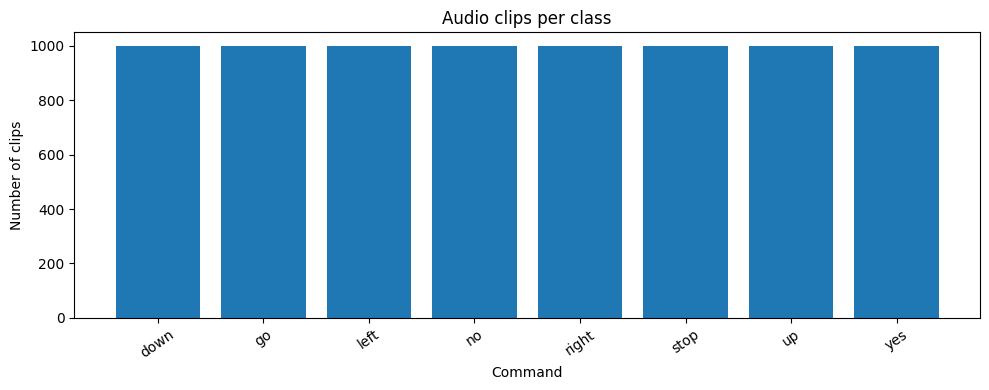

Example: 6ef76186_nohash_3.wav | sample rate: 16000


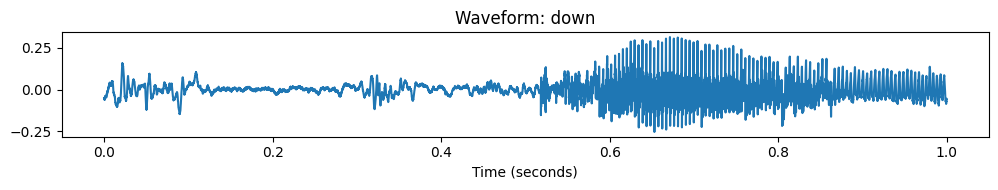

In [ ]:
counts = {c: len(list((DATA_DIR / c).glob("*.wav"))) for c in class_names}
plt.figure(figsize=(10, 4))
plt.bar(counts.keys(), counts.values())
plt.title("Audio clips per class")
plt.xlabel("Command")
plt.ylabel("Number of clips")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

example_path = next((DATA_DIR / class_names[0]).glob("*.wav"))
example_audio, example_sr = sf.read(example_path)
if example_audio.ndim > 1:
    example_audio = example_audio.mean(axis=1)
print("Example:", example_path.name, "| sample rate:", example_sr)
plt.figure(figsize=(10, 2))
plt.plot(np.arange(len(example_audio)) / example_sr, example_audio)
plt.title(f"Waveform: {class_names[0]}")
plt.xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

## 5. Convert audio into log-Mel spectrograms

In [ ]:
SAMPLE_RATE = 16000
DURATION = 1.0
NUM_SAMPLES = int(SAMPLE_RATE * DURATION)
N_MELS = 64
N_FFT = 512
HOP_LENGTH = 256
MAX_PER_CLASS = 1200  # Set to None to use all available files.

def load_audio_mono(path):
    y, sr = sf.read(path)
    if y.ndim > 1:
        y = y.mean(axis=1)
    y = y.astype(np.float32)
    if sr != SAMPLE_RATE:
        y = librosa.resample(y, orig_sr=sr, target_sr=SAMPLE_RATE)
    if len(y) < NUM_SAMPLES:
        y = np.pad(y, (0, NUM_SAMPLES - len(y)))
    else:
        y = y[:NUM_SAMPLES]
    return y.astype(np.float32)

def audio_to_logmel(y):
    mel = librosa.feature.melspectrogram(
        y=y, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=50, fmax=7600
    )
    logmel = librosa.power_to_db(mel, ref=np.max)
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)
    return logmel.astype(np.float32)

X_list, labels_list, paths_list = [], [], []
for cls in class_names:
    files = list((DATA_DIR / cls).glob("*.wav"))
    random.shuffle(files)
    if MAX_PER_CLASS is not None:
        files = files[:MAX_PER_CLASS]
    for wav_path in files:
        try:
            waveform = load_audio_mono(wav_path)
            X_list.append(audio_to_logmel(waveform))
            labels_list.append(cls)
            paths_list.append(str(wav_path))
        except Exception as e:
            print("Skipping", wav_path, ":", e)

X = np.asarray(X_list, dtype=np.float32)[..., np.newaxis]
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(np.asarray(labels_list))
NUM_CLASSES = len(label_encoder.classes_)

print("Feature shape:", X.shape)
print("Classes:", list(label_encoder.classes_))

Feature shape: (8000, 64, 63, 1)
Classes: [np.str_('down'), np.str_('go'), np.str_('left'), np.str_('no'), np.str_('right'), np.str_('stop'), np.str_('up'), np.str_('yes')]


## 6. Split training, validation, and test data

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print("Training:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Training: (5600, 64, 63, 1) Validation: (1200, 64, 63, 1) Test: (1200, 64, 63, 1)


## 7. Build the CNN

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.30),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 63, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 63, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 31, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,112 (434.03 KB)

 Trainable params: 110,664 (432.28 KB)

 Non-trainable params: 448 (1.75 KB)

## 8. Train the CNN

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_audio_cnn.keras", monitor="val_loss", save_best_only=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 63s 679ms/step - accuracy: 0.4223 - loss: 1.5589 - val_accuracy: 0.1275 - val_loss: 2.4873 - learning_rate: 0.0010
Epoch 2/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 80s 668ms/step - accuracy: 0.6918 - loss: 0.8882 - val_accuracy: 0.1692 - val_loss: 3.6802 - learning_rate: 0.0010
Epoch 3/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 81s 656ms/step - accuracy: 0.8102 - loss: 0.5753 - val_accuracy: 0.2167 - val_loss: 4.3183 - learning_rate: 0.0010
Epoch 4/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 83s 668ms/step - accuracy: 0.8763 - loss: 0.3964 - val_accuracy: 0.3067 - val_loss: 3.4735 - learning_rate: 5.0000e-04
Epoch 5/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 58s 655ms/step - accuracy: 0.9004 - loss: 0.3185 - val_accuracy: 0.5367 - val_loss: 1.7382 - learning_rate: 5.0000e-04
Epoch 6/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 59s 674ms/step - accuracy: 0.9189 - loss: 0.2628 - val_accuracy: 0.7767 - val_loss: 0.6581 - learning_rate: 5.0000e-04
Epoch 7/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 80s 654ms/step - accuracy: 0.926

## 9. Plot training curves

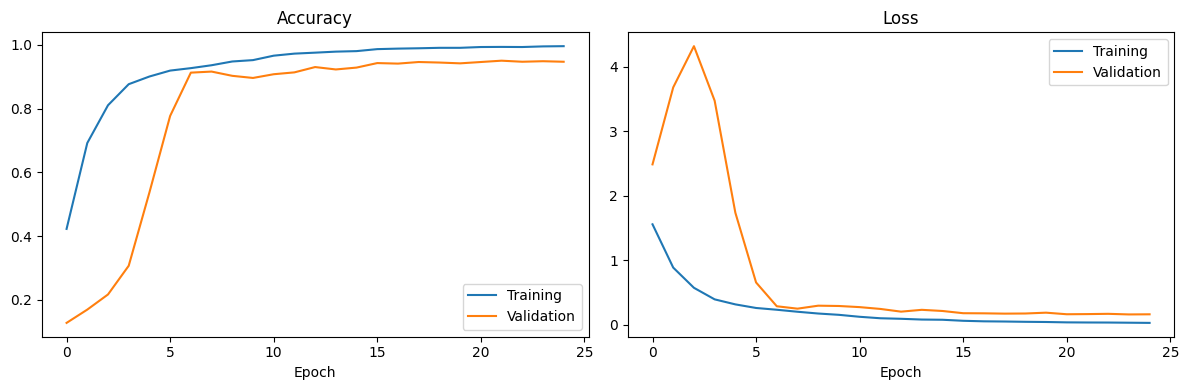

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Evaluate the CNN

Test accuracy      : 0.9367
Weighted precision : 0.9381
Weighted recall    : 0.9367
Weighted F1-score  : 0.9368

Classification report:
              precision    recall  f1-score   support

        down       0.95      0.91      0.93       150
          go       0.90      0.95      0.92       150
        left       0.93      0.93      0.93       150
          no       0.95      0.89      0.92       150
       right       0.97      0.96      0.97       150
        stop       0.97      0.93      0.95       150
          up       0.88      0.97      0.92       150
         yes       0.95      0.95      0.95       150

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200



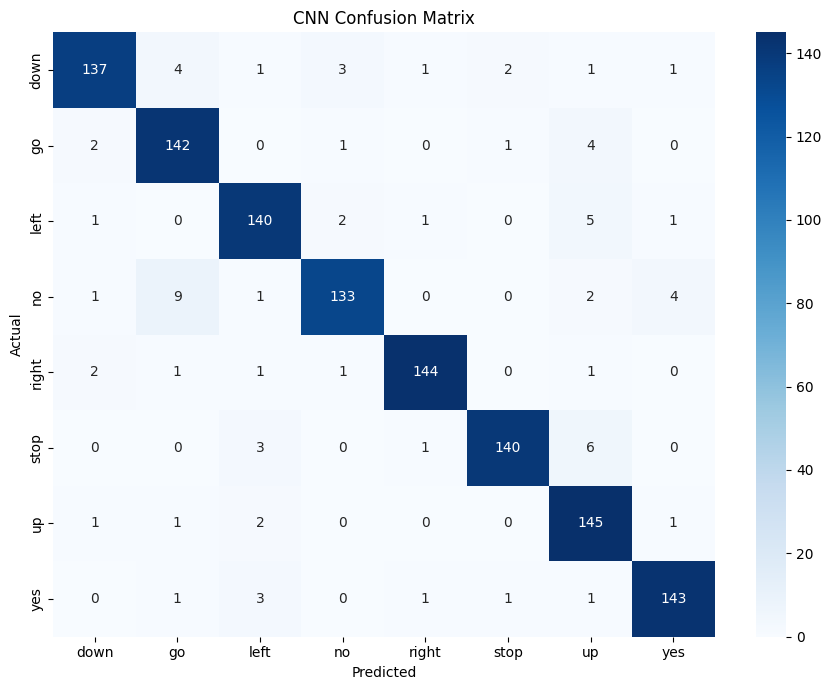

In [ ]:
test_probs = model.predict(X_test, batch_size=64, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0
)
print(f"Test accuracy      : {test_accuracy:.4f}")
print(f"Weighted precision : {precision:.4f}")
print(f"Weighted recall    : {recall:.4f}")
print(f"Weighted F1-score  : {f1:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred, target_names=label_encoder.classes_, zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Save the model and labels

In [ ]:
model.save("audio_command_cnn.keras")
with open("label_classes.json", "w") as f:
    json.dump(label_encoder.classes_.tolist(), f)
print("Saved audio_command_cnn.keras and label_classes.json")

Saved audio_command_cnn.keras and label_classes.json


## 12. Initialize Whisper STT

The warnings about deprecated `forced_decoder_ids` or generation settings are usually non-fatal. This cell suppresses only those known deprecation warnings; real exceptions will still be displayed. Whisper downloads model files on the first run.

In [ ]:
import torch
from transformers import pipeline

warnings.filterwarnings(
    "ignore",
    message=".*forced_decoder_ids.*",
    category=UserWarning
)
warnings.filterwarnings(
    "ignore",
    message=".*generation_config.*",
    category=UserWarning
)

stt_device = 0 if torch.cuda.is_available() else -1
try:
    stt_pipe = pipeline(
        "automatic-speech-recognition",
        model="openai/whisper-tiny.en",
        device=stt_device
    )
    print("Whisper initialized on", "GPU" if stt_device == 0 else "CPU")
except Exception as e:
    stt_pipe = None
    print("Whisper initialization failed:", repr(e))
    print("The CNN classification part can still be used.")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

Whisper initialized on CPU


## 13. Initialize TTS

In [ ]:
from gtts import gTTS
from IPython.display import Audio, display

def speak_text(text, lang="en"):
    text = str(text).strip()
    if not text:
        print("No text supplied to TTS.")
        return
    output_path = "tts_output.mp3"
    gTTS(text=text, lang=lang).save(output_path)
    display(Audio(filename=output_path, autoplay=False))
    return output_path

print("TTS function ready. gTTS requires an internet connection.")

TTS function ready. gTTS requires an internet connection.


## 14. Upload an audio file

In [15]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise ValueError("No file uploaded. Please upload a WAV or MP3 file.")

uploaded_audio_path = next(iter(uploaded.keys()))
if not os.path.exists(uploaded_audio_path):
    raise FileNotFoundError(f"Uploaded file is not available: {uploaded_audio_path}")

print("Uploaded:", uploaded_audio_path)

Saving no.wav to no.wav
Uploaded: no.wav


## 15. End-to-end test: STT + CNN classification + TTS

Upload a real recording of a single supported command for meaningful results. The included synthetic test file contains no speech, so STT will not produce a useful transcript.

In [16]:
def prepare_audio_file(path):
    y_audio, sr_audio = librosa.load(path, sr=SAMPLE_RATE, mono=True)
    if len(y_audio) < NUM_SAMPLES:
        y_audio = np.pad(y_audio, (0, NUM_SAMPLES - len(y_audio)))
    else:
        y_audio = y_audio[:NUM_SAMPLES]
    return y_audio.astype(np.float32)

if "uploaded_audio_path" not in globals():
    raise NameError("Run the upload cell immediately above this cell first.")

if not os.path.isfile(uploaded_audio_path):
    raise FileNotFoundError(
        f"Could not find {uploaded_audio_path}. Please run the upload cell again."
    )

demo_wave = prepare_audio_file(uploaded_audio_path)
print("Audio loaded:", uploaded_audio_path, "| samples:", len(demo_wave))

# STT is independent of the CNN classifier.
transcript = ""
if stt_pipe is not None:
    try:
        stt_result = stt_pipe(uploaded_audio_path)
        transcript = stt_result.get("text", "").strip()
    except Exception as e:
        print("STT failed:", repr(e))
else:
    print("STT unavailable: Whisper was not initialized.")

print("STT transcript:", transcript if transcript else "(No speech recognized)")

# CNN classification
demo_features = audio_to_logmel(demo_wave)[np.newaxis, ..., np.newaxis]
demo_probabilities = model.predict(demo_features, verbose=0)[0]
pred_idx = int(np.argmax(demo_probabilities))
predicted_command = str(label_encoder.classes_[pred_idx])
confidence = float(demo_probabilities[pred_idx])

print("\nPredicted command:", predicted_command)
print(f"Model confidence: {confidence:.2%}")
print("\nTop 3 predictions:")
for idx in np.argsort(demo_probabilities)[::-1][:3]:
    print(f"{label_encoder.classes_[idx]}: {demo_probabilities[idx]:.2%}")

# TTS errors do not erase STT or classification results.
try:
    speak_text(f"The predicted command is {predicted_command}.")
except Exception as e:
    print("TTS failed:", repr(e))

Audio loaded: no.wav | samples: 16000


[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


STT transcript: No.

Predicted command: go
Model confidence: 64.08%

Top 3 predictions:
go: 64.08%
no: 35.46%
down: 0.40%


## 16. Export the evaluation metrics

In [17]:
results = pd.DataFrame([{
    "Model": "CNN on log-Mel spectrograms",
    "Dataset": "Mini Speech Commands",
    "Test Accuracy": test_accuracy,
    "Weighted Precision": precision,
    "Weighted Recall": recall,
    "Weighted F1-score": f1,
    "Training Samples": len(X_train),
    "Validation Samples": len(X_val),
    "Test Samples": len(X_test)
}])
display(results.round(4))
results.to_csv("audio_classification_metrics.csv", index=False)
print("Saved audio_classification_metrics.csv")

,Model,Dataset,Test Accuracy,Weighted Precision,Weighted Recall,Weighted F1-score,Training Samples,Validation Samples,Test Samples
0,CNN on log-Mel spectrograms,Mini Speech Commands,0.9367,0.9381,0.9367,0.9368,5600,1200,1200


Saved audio_classification_metrics.csv


## 17. Conclusion template

After running the notebook, insert your actual measured metrics:

A CNN-based audio classification system was developed using log-Mel spectrograms from the Mini Speech Commands dataset. Performance was evaluated using test accuracy, weighted precision, weighted recall, weighted F1-score, a classification report, and a confusion matrix. Whisper was integrated for speech-to-text transcription and gTTS for text-to-speech output. The model's measured performance is shown in the evaluation section. Accuracy may be lower for noisy recordings, unfamiliar speakers, or audio that does not contain one of the supported commands.

**Troubleshooting**
- If the runtime resets, rerun cells from the beginning.
- If the dataset or Whisper download fails, check internet access and rerun the relevant cell.
- If GPU memory is low, set `MAX_PER_CLASS = 500` and rerun from the feature extraction cell.
- If TTS fails, the CNN and STT outputs may still be available; gTTS requires internet.